# Transformer の実装

**PyTorch の線形層と活性化関数から組み立てる、デコーダ型 Transformer の実装**です。
`nn.Transformer` のような既製モジュールは使わず、次の処理を実行します。

- スケール化内積注意・マルチヘッド注意・フィードフォワード層・残差接続・層正規化・因果マスクを、部品ごとに実装して動作を確認する
- 短いコーパスで次トークン予測を学習し、損失の推移を確かめる
- 学習前後の生成テキストを比べ、コーパスの暗記と一般化の違いを観察する

前半では、ダミー入力で形や計算を確かめながら Transformer を実装します。
後半の実験では、桃太郎の本文を使って文字レベル言語モデルを学習させ、生成結果を観察します。

## セットアップ

必要なライブラリを入れます。Transformer の本体は PyTorch の基本要素だけで書き、可視化に matplotlib を使います。

In [1]:
!pip install -q torch  # ニューラルネットワークの構築と学習
!pip install -q matplotlib  # 損失曲線・注意の重みの可視化
!pip install -q japanize_matplotlib  # matplotlib のグラフを日本語表示にする
!pip install -q setuptools  # 日本語フォント設定の互換性

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 44.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## Transformer の実装

注意機構から順に部品を実装し、最後にデコーダ型 Transformer を組み立てます。
動作確認にはランダムなベクトルやトークン ID を使います。

### スケール化内積注意と因果マスク

まず注意機構から実装します。

注意機構は、各位置が他の位置の情報をどれだけ参照するかを重みで決め、情報を混ぜ合わせる処理です。クエリは「探したい情報」、キーは「照合する情報」、バリューは「集約する内容」を表すベクトルです。全位置のベクトルを行に並べた行列 $\mathbf{Q}, \mathbf{K}, \mathbf{V}$ を使い、系列全体をまとめて計算します。

$$\mathrm{Att}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \mathrm{Softmax}\!\left(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d}} + \mathbf{M}\right)\mathbf{V}$$

- 内積 $\mathbf{Q}\mathbf{K}^\top$ でクエリとキーの関係の強さを測り、$\sqrt{d}$ で割って値のスケールを安定させます（$d$ はクエリとキーのベクトルの次元数です）。
- **因果マスク** $\mathbf{M}$ は、未来の位置（$t' > t$）に $-\infty$ を加えて注意の重みを 0 にし、各位置が過去と自分自身だけを見るようにします。

Softmax は各行を合計1の重みに変換します。`@` は行列積、`transpose` は行と列の入れ替えです。注意の計算とマスク作りを、それぞれ関数にします。

In [2]:
import math

import torch

import torch.nn.functional as F


def causal_mask(seq_len: int) -> torch.Tensor:
    """未来の位置を -inf でふさぐ加法マスク M（seq_len x seq_len）を作る。"""
    mask = torch.full((seq_len, seq_len), float("-inf"))
    return torch.triu(mask, diagonal=1)  # 対角より上（未来）だけ -inf、それ以外は 0


def scaled_dot_product_attention(
    q: torch.Tensor,
    k: torch.Tensor,
    v: torch.Tensor,
    mask: torch.Tensor | None = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    """スケール化内積注意。出力と注意の重みを返す。"""
    d = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d)  # Z = QK^T / sqrt(d)
    if mask is not None:
        scores = scores + mask
    weights = F.softmax(scores, dim=-1)  # 行ごとに正規化した注意の重み s
    return weights @ v, weights

#### 動作確認：因果マスクは重みをどう変えるか

小さなダミー入力（5 個のベクトル）で注意の重みを計算し、ヒートマップで見てみます。
因果マスクを入れると、各行（クエリ）は自分より右（未来）の列に重みを置けなくなり、下三角の形になるはずです。

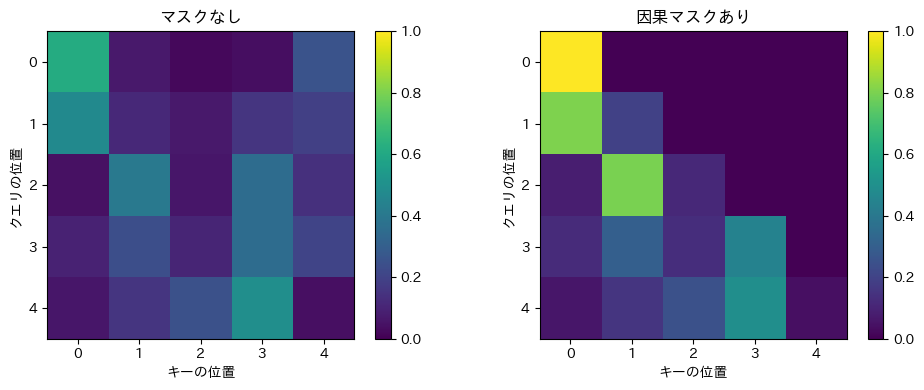

In [3]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # import するだけでグラフが日本語表示になる

torch.manual_seed(0)  # 再現性のためにシードを固定する
q = torch.randn(5, 8)
k = torch.randn(5, 8)
v = torch.randn(5, 8)

_, w_nomask = scaled_dot_product_attention(q, k, v)
_, w_masked = scaled_dot_product_attention(q, k, v, mask=causal_mask(5))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, w, title in zip(axes, [w_nomask, w_masked], ["マスクなし", "因果マスクあり"]):
    im = ax.imshow(w.detach(), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("キーの位置")
    ax.set_ylabel("クエリの位置")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

右の図では、対角線より上（未来のキー）の重みがすべて 0 になり、下三角形になっています。
各位置が過去と自分自身だけに注意を向ける、という因果性が実現できました。

### マルチヘッド注意機構

注意を 1 組だけでなく複数の**ヘッド**に分けて並列に計算し、最後に統合します。
(1) ヘッドごとに線形変換で次元数を減らし、(2) 各ヘッドで注意を計算し、(3) 結果を連結して線形変換します。

実装上の工夫として、ヘッドごとの重み行列 $\mathbf{W}_i^Q, \mathbf{W}_i^K, \mathbf{W}_i^V$ をヘッド数ぶん個別に持つ代わりに、**1 つの `nn.Linear` でまとめて計算してからヘッド数に切り分けます**。各ヘッドの出力を1つの行列として計算し、その後で分割する方法です。
自己注意なので、クエリ・キー・バリューはすべて同じ入力 $\mathbf{X}$ から作ります。

`MultiHeadAttention` は全位置ぶんの自己注意 $\mathrm{SelfAtt}(\mathbf{X})$ をまとめて返すクラスです。`nn.Module` は、学習する層や重みをまとめる PyTorch の基本クラスで、`forward` に入力から出力への計算を書きます。因果マスクもこの中で適用します。

In [4]:
import torch.nn as nn


class MultiHeadAttention(nn.Module):
    """全位置の SelfAtt(X) を計算する、因果マスク付きのマルチヘッド自己注意。"""

    def __init__(self, d_model: int, num_heads: int) -> None:
        super().__init__()
        assert (
            d_model % num_heads == 0
        ), "d_model は num_heads で割り切れる必要があります"
        self.num_heads = num_heads
        self.d_head = d_model // num_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)  # 連結後の統合用の線形変換

    def _split_heads(self, x: torch.Tensor) -> torch.Tensor:
        """(batch, seq, d_model) を (batch, num_heads, seq, d_head) に並べ替える。"""
        batch, seq, _ = x.shape
        return x.view(batch, seq, self.num_heads, self.d_head).transpose(1, 2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch, seq, _ = x.shape
        # 自己注意：クエリ・キー・バリューはすべて同じ入力から作る
        q = self._split_heads(self.W_q(x))
        k = self._split_heads(self.W_k(x))
        v = self._split_heads(self.W_v(x))

        mask = causal_mask(seq).to(x.device)
        out, _ = scaled_dot_product_attention(q, k, v, mask)  # 各ヘッドで独立に注意

        # ヘッドを連結して (batch, seq, d_model) に戻し、線形変換で統合する
        out = out.transpose(1, 2).reshape(batch, seq, -1)
        return self.W_o(out)

自己注意は「各位置の表現を文脈で更新する」処理なので、入力と出力の形（系列長・次元）は変わりません。ダミー入力で確かめます。

In [5]:
seq_len = 32  # 部品の動作確認に使うダミー系列の長さ

mha = MultiHeadAttention(d_model=64, num_heads=4)
dummy = torch.randn(2, seq_len, 64)  # (batch, seq, d_model)
print("入力 :", tuple(dummy.shape))
print("出力 :", tuple(mha(dummy).shape))

入力 : (2, 32, 64)
出力 : (2, 32, 64)


### 層正規化

各ベクトルを特徴量方向（$d$ 次元）で平均 0・分散 1 にそろえ、学習可能なスケール $\gamma$ とバイアス $\beta$ をかけます。

$$\mathrm{LayerNorm}(\mathbf{x}) = \gamma \odot \frac{\mathbf{x} - \mu}{\sigma + \epsilon} + \beta$$

$\epsilon$ は $\sigma$ が 0 に近いときのゼロ除算を防ぐ小さな定数で、$10^{-5}$ を使います。式の通りに素直に実装します。

In [6]:
class LayerNorm(nn.Module):
    """特徴量方向で正規化し、学習可能なスケールとバイアスをかける層。"""

    def __init__(self, dim: int, eps: float = 1e-5) -> None:
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(dim))
        self.beta = nn.Parameter(torch.zeros(dim))
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mu = x.mean(dim=-1, keepdim=True)
        sigma = x.std(dim=-1, keepdim=True, unbiased=False)
        return self.gamma * (x - mu) / (sigma + self.eps) + self.beta

#### 動作確認：出力の平均と標準偏差

スケールがバラバラなダミー入力を通し、出力が特徴量方向で平均 0・標準偏差 1 に近づくことを確認します（初期値では $\gamma=1, \beta=0$）。

In [7]:
norm = LayerNorm(64)
x = torch.randn(2, seq_len, 64) * 5 + 3  # わざと平均・分散をずらした入力
out = norm(x)
print(f"入力  の平均 {x.mean():+.3f}  標準偏差 {x.std():.3f}")
mean_per_vec = out.mean(dim=-1)  # 各位置のベクトルごとに見る
std_per_vec = out.std(dim=-1, unbiased=False)
print(
    f"正規化後（各位置ごと）の平均 {mean_per_vec.abs().max():+.3f} 以下  "
    f"標準偏差 {std_per_vec.mean():.3f}"
)

入力  の平均 +2.958  標準偏差 5.126
正規化後（各位置ごと）の平均 +0.000 以下  標準偏差 1.000


### フィードフォワード層

各位置のベクトルに、位置ごとに独立して非線形変換をかけます。
2 層の線形変換の間に活性化関数 $\mathrm{Act}$ を挟む構造です。

$$\mathrm{FFN}(\mathbf{x}) = \mathrm{Act}(\mathbf{x}\mathbf{W}_1 + \mathbf{b}_1)\mathbf{W}_2 + \mathbf{b}_2$$

活性化関数は、原論文の ReLU に対し、近年よく使われる GELU を採用します。中間次元 $d_{\mathrm{ff}}$ は $d$ より大きく取るのが一般的です。

In [8]:
class FeedForward(nn.Module):
    """2 層の線形変換の間に活性化関数を挟むフィードフォワード層。"""

    def __init__(self, d_model: int, d_ff: int) -> None:
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.act = nn.GELU()
        self.w2 = nn.Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.w2(self.act(self.w1(x)))

フィードフォワード層は各位置を個別に加工するだけなので、入力と出力の形は変わりません。

In [9]:
ffn = FeedForward(d_model=64, d_ff=256)
dummy = torch.randn(2, seq_len, 64)
print("入力 :", tuple(dummy.shape))
print("出力 :", tuple(ffn(dummy).shape))

入力 : (2, 32, 64)
出力 : (2, 32, 64)


### デコーダブロック（残差接続 + 層正規化）

ここまでの部品を、残差接続と層正規化でつないで 1 層分にまとめます。
ここでは、残差接続で足し戻す前に正規化する Pre-LN 形式を使います（モジュールに入れる前に `LayerNorm` を通す形です）。

$$\mathbf{H} = \mathbf{X} + \mathrm{SelfAtt}(\mathrm{LayerNorm}(\mathbf{X})), \qquad
\mathbf{X}' = \mathbf{H} + \mathrm{FFN}(\mathrm{LayerNorm}(\mathbf{H}))$$

式の $\mathrm{SelfAtt}$ は、いま実装した `MultiHeadAttention` に対応します。

残差接続（`x + ...`）が「入力をそのまま通す経路」を確保し、深いネットワークでも勾配が伝わりやすくなります。

In [10]:
class DecoderBlock(nn.Module):
    """Pre-LN 形式で自己注意とフィードフォワードを残差接続でつなぐ層。"""

    def __init__(self, d_model: int, num_heads: int, d_ff: int) -> None:
        super().__init__()
        self.norm1 = LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, num_heads)
        self.norm2 = LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

デコーダブロックは入力表現を更新して返すだけなので、系列長も次元も変わりません。

In [11]:
block = DecoderBlock(d_model=64, num_heads=4, d_ff=256)
dummy = torch.randn(2, seq_len, 64)
print("入力 :", tuple(dummy.shape))
print("出力 :", tuple(block(dummy).shape))

入力 : (2, 32, 64)
出力 : (2, 32, 64)


形が保たれているので、この層を何段でも積み重ねられます。次はいよいよ全体を組み立てます。

### 統合：デコーダ型 Transformer

部品を組み合わせて全体を作ります。処理の流れは次の通りです。

1. **埋め込み層**：トークン ID をベクトルに変換。
2. **位置エンコーディング**：位置ごとのベクトルを足して語順の情報を与えます。ここでは、**学習型**（位置ごとのベクトルをパラメータとして学習する `nn.Embedding`）を使います。これを足さないと、自己注意は語順を区別できません。
3. **デコーダブロック × $L$**：自己注意とフィードフォワードで表現を更新。
4. **出力用の線形変換** $\mathbf{W}_{\mathrm{out}}$：最終表現を語彙サイズのスコア（logits）に写す。

デコーダブロックを通したあと、出力用の線形変換に入れる前に層正規化（`final_norm`）を 1 つ挟みます。Pre-LN では残差接続の経路が最後まで正規化されないため、出力の直前でスケールをそろえる役割です。

logits に Softmax をかければ、次トークンの確率分布 $p(w \mid w_1,\ldots,w_{t-1})$ になります。

In [12]:
class DecoderTransformer(nn.Module):
    """デコーダ型 Transformer。文脈から各位置の次トークン logits を出力する。"""

    def __init__(
        self,
        vocab_size: int,
        d_model: int = 64,
        num_heads: int = 4,
        num_layers: int = 2,
        d_ff: int = 256,
        max_len: int = 32,
    ) -> None:
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList(
            [DecoderBlock(d_model, num_heads, d_ff) for _ in range(num_layers)]
        )
        self.final_norm = LayerNorm(d_model)
        self.output = nn.Linear(d_model, vocab_size)  # W_out：logits への写像

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        _, seq = idx.shape
        positions = torch.arange(seq, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)
        return self.output(x)  # (batch, seq, vocab_size)


ダミーのトークン ID を入力して、モデル全体の出力を確認します。
ここでは動作確認用に語彙サイズを 100 と置きます。実際の語彙と学習用のモデルは、後半の実験で用意します。

In [13]:
dummy_vocab_size = 100
dummy_model = DecoderTransformer(vocab_size=dummy_vocab_size, max_len=seq_len)
dummy_ids = torch.randint(dummy_vocab_size, (2, seq_len))
print("入力 ID:", tuple(dummy_ids.shape))
print("出力 logits:", tuple(dummy_model(dummy_ids).shape))

入力 ID: (2, 32)
出力 logits: (2, 32, 100)


出力は `(2, 32, 100)` です。各系列の各位置について、次のトークン候補 100 個ぶんのスコアが得られます。
これで Transformer の実装ができました。ここからは実際のテキストを使って、学習と生成を試します。

## 実験：テキストで学習し、生成する

ここから学習データを用意します。本文の文字 ID への変換、入力と正解の作成を行い、
前半で実装した Transformer を使って次トークン予測の学習と生成を試します。

### 学習コーパスを用意する

青空文庫に収録されている[『桃太郎』](https://www.aozora.gr.jp/cards/000329/card18376.html)の本文を学習してみましょう。

ここでは、短時間で、学習が動いているかどうかを確認できれば良いので、この１つのデータにモデルがフィットできるかどうかを確認します。

In [14]:
STORY = """桃太郎
　むかし、むかし、あるところに、おじいさんとおばあさんがありました。まいにち、おじいさんは山へしば刈《か》りに、おばあさんは川へ洗濯《せんたく》に行きました。
　ある日、おばあさんが、川のそばで、せっせと洗濯《せんたく》をしていますと、川上《かわかみ》から、大きな桃《もも》が一つ、

「ドンブラコッコ、スッコッコ。
ドンブラコッコ、スッコッコ。」

　と流《なが》れて来《き》ました。
「おやおや、これはみごとな桃《もも》だこと。おじいさんへのおみやげに、どれどれ、うちへ持《も》って帰《かえ》りましょう。」
　おばあさんは、そう言《い》いながら、腰《こし》をかがめて桃《もも》を取《と》ろうとしましたが、遠《とお》くって手がとどきません。おばあさんはそこで、

「あっちの水《みいず》は、かあらいぞ。
こっちの水《みいず》は、ああまいぞ。
かあらい水《みいず》は、よけて来《こ》い。
ああまい水《みいず》に、よって来《こ》い。

　と歌《うた》いながら、手をたたきました。すると桃《もも》はまた、

「ドンブラコッコ、スッコッコ。

　といいながら、おばあさんの前《まえ》へ流《なが》れて来《き》ました。おばあさんはにこにこしながら、
「早《はや》くおじいさんと二人《ふたり》で分《わ》けて食《た》べましょう。」
　と言《い》って、桃《もも》をひろい上《あ》げて、洗濯物《せんたくもの》といっしょにたらいの中に入《い》れて、えっちら、おっちら、かかえておうちへ帰《かえ》りました。
　夕方《ゆうがた》になってやっと、おじいさんは山からしばを背負《せお》って帰《かえ》って来《き》ました。
「おばあさん、今《いま》帰《かえ》ったよ。」
「おや、おじいさん、おかいんなさい。待《ま》っていましたよ。さあ、早《はや》くお上《あ》がんなさい。いいものを上《あ》げますから。」
「それはありがたいな。何《なん》だね、そのいいものというのは。」
　こういいながら、おじいさんはわらじをぬいで、上に上《あ》がりました。その間《ま》に、おばあさんは戸棚《とだな》の中からさっきの桃《もも》を重《おも》そうにかかえて来《き》て、
「ほら、ごらんなさいこの桃《もも》を。」
　と言《い》いました。
「ほほう、これはこれは。どこからこんなみごとな桃《もも》を買《か》って来《き》た。」
「いいえ、買《か》って来《き》たのではありません。今日《きょう》川で拾《ひろ》って来《き》たのですよ。」
「え、なに、川で拾《ひろ》って来《き》た。それはいよいよめずらしい。」
　こうおじいさんは言《い》いながら、桃《もも》を両手《りょうて》にのせて、ためつ、すがめつ、ながめていますと、だしぬけに、桃《もも》はぽんと中から二つに割《わ》れて、
「おぎゃあ、おぎゃあ。」
　と勇《いさ》ましいうぶ声《こえ》を上《あ》げながら、かわいらしい赤《あか》さんが元気《げんき》よくとび出《だ》しました。
「おやおや、まあ。」
　おじいさんも、おばあさんも、びっくりして、二人《ふたり》いっしょに声《こえ》を立《た》てました。
「まあまあ、わたしたちが、へいぜい、どうかして子供《こども》が一人《ひとり》ほしい、ほしいと言《い》っていたものだから、きっと神《かみ》さまがこの子をさずけて下《くだ》さったにちがいない。」
　おじいさんも、おばあさんも、うれしがって、こう言《い》いました。
　そこであわてておじいさんがお湯《ゆ》をわかすやら、おばあさんがむつきをそろえるやら、大《おお》さわぎをして、赤《あか》さんを抱《だ》き上《あ》げて、うぶ湯《ゆ》をつかわせました。するといきなり、
「うん。」
　と言《い》いながら、赤《あか》さんは抱《だ》いているおばあさんの手をはねのけました。
「おやおや、何《なん》という元気《げんき》のいい子だろう。」
　おじいさんとおばあさんは、こう言《い》って顔《かお》を見合《みあ》わせながら、「あッは、あッは。」とおもしろそうに笑《わら》いました。
　そして桃《もも》の中から生《う》まれた子だというので、この子に桃太郎《ももたろう》という名《な》をつけました。


　おじいさんとおばあさんは、それはそれはだいじにして桃太郎《ももたろう》を育《そだ》てました。桃太郎《ももたろう》はだんだん成長《せいちょう》するにつれて、あたりまえの子供《こども》にくらべては、ずっと体《からだ》も大きいし、力《ちから》がばかに強《つよ》くって、すもうをとっても近所《きんじょ》の村《むら》じゅうで、かなうものは一人《ひとり》もないくらいでしたが、そのくせ気《き》だてはごくやさしくって、おじいさんとおばあさんによく孝行《こうこう》をしました。
　桃太郎《ももたろう》は十五になりました。
　もうそのじぶんには、日本《にほん》の国中《くにじゅう》で、桃太郎《ももたろう》ほど強《つよ》いものはないようになりました。桃太郎《ももたろう》はどこか外国《がいこく》へ出かけて、腕《うで》いっぱい、力《ちから》だめしをしてみたくなりました。
　するとそのころ、ほうぼう外国《がいこく》の島々《しまじま》をめぐって帰《かえ》って来《き》た人があって、いろいろめずらしい、ふしぎなお話《はなし》をした末《すえ》に、
「もう何年《なんねん》も何年《なんねん》も船《ふね》をこいで行くと、遠《とお》い遠《とお》い海《うみ》のはてに、鬼《おに》が島《しま》という所《ところ》がある。悪《わる》い鬼《おに》どもが、いかめしいくろがねのお城《しろ》の中に住《す》んで、ほうぼうの国《くに》からかすめ取《と》った貴《とうと》い宝物《たからもの》を守《まも》っている。」
　と言《い》いました。
　桃太郎《ももたろう》はこの話《はなし》をきくと、その鬼《おに》が島《しま》へ行ってみたくって、もう居《い》ても立《た》ってもいられなくなりました。そこでうちへ帰《かえ》るとさっそく、おじいさんの前《まえ》へ出て、
「どうぞ、わたくしにしばらくおひまを下《くだ》さい。」
　と言《い》いました。
　おじいさんはびっくりして、
「お前《まえ》どこへ行くのだ。」
　と聞《き》きました。
「鬼《おに》が島《しま》へ鬼《おに》せいばつに行こうと思《おも》います。」
　と桃太郎《ももたろう》はこたえました。
「ほう、それはいさましいことだ。じゃあ行っておいで。」
　とおじいさんは言《い》いました。
「まあ、そんな遠方《えんぽう》へ行くのでは、さぞおなかがおすきだろう。よしよし、おべんとうをこしらえて上《あ》げましょう。」
　とおばあさんも言《い》いました。
　そこで、おじいさんとおばあさんは、お庭《にわ》のまん中に、えんやら、えんやら、大きな臼《うす》を持《も》ち出《だ》して、おじいさんがきねを取《と》ると、おばあさんはこねどりをして、
「ぺんたらこっこ、ぺんたらこっこ。ぺんたらこっこ、ぺんたらこっこ。」
　と、おべんとうのきびだんごをつきはじめました。
　きびだんごがうまそうにでき上《あ》がると、桃太郎《ももたろう》のしたくもすっかりでき上《あ》がりました。
　桃太郎《ももたろう》はお侍《さむらい》の着《き》るような陣羽織《じんばおり》を着《き》て、刀《かたな》を腰《こし》にさして、きびだんごの袋《ふくろ》をぶら下《さ》げました。そして桃《もも》の絵《え》のかいてある軍扇《ぐんせん》を手に持《も》って、
「ではおとうさん、おかあさん、行ってまいります。」
　と言《い》って、ていねいに頭《あたま》を下《さ》げました。
「じゃあ、りっぱに鬼《おに》を退治《たいじ》してくるがいい。」
　とおじいさんは言《い》いました。
「気《き》をつけて、けがをしないようにおしよ。」
　とおばあさんも言《い》いました。
「なに、大丈夫《だいじょうぶ》です、日本一《にっぽんいち》のきびだんごを持《も》っているから。」と桃太郎《ももたろう》は言《い》って、
「では、ごきげんよう。」
　と元気《げんき》な声《こえ》をのこして、出《で》ていきました。おじいさんとおばあさんは、門《もん》の外《そと》に立《た》って、いつまでも、いつまでも見送《みおく》っていました。


　桃太郎《ももたろう》はずんずん行きますと、大きな山の上に来《き》ました。すると、草《くさ》むらの中から、「ワン、ワン。」と声《こえ》をかけながら、犬《いぬ》が一ぴきかけて来《き》ました。
　桃太郎《ももたろう》がふり返《かえ》ると、犬《いぬ》はていねいに、おじぎをして、
「桃太郎《ももたろう》さん、桃太郎《ももたろう》さん、どちらへおいでになります。」
　とたずねました。
「鬼《おに》が島《しま》へ、鬼《おに》せいばつに行くのだ。」
「お腰《こし》に下《さ》げたものは、何《なん》でございます。」
「日本《にっぽん》一のきびだんごさ。」
「一つ下《くだ》さい、お供《とも》しましょう。」
「よし、よし、やるから、ついて来《こ》い。」
　犬《いぬ》はきびだんごを一つもらって、桃太郎《ももたろう》のあとから、ついて行きました。
　山を下《お》りてしばらく行《い》くと、こんどは森《もり》の中にはいりました。すると木の上から、「キャッ、キャッ。」とさけびながら、猿《さる》が一ぴき、かけ下《お》りて来《き》ました。
　桃太郎《ももたろう》がふり返《かえ》ると、猿《さる》はていねいに、おじぎをして、
「桃太郎《ももたろう》さん、桃太郎《ももたろう》さん、どちらへおいでになります。」
　とたずねました。
「鬼《おに》が島《しま》へ鬼《おに》せいばつに行くのだ。」
「お腰《こし》に下《さ》げたものは、何《なん》でございます。」
「日本《にっぽん》一のきびだんごさ。」
「一つ下《くだ》さい、お供《とも》しましょう。」
「よし、よし、やるから、ついて来《こ》い。」
　猿《さる》もきびだんごを一つもらって、あとからついて行きました。
　山を下《お》りて、森《もり》をぬけて、こんどはひろい野原《のはら》へ出ました。すると空《そら》の上で、「ケン、ケン。」と鳴《な》く声《こえ》がして、きじが一｜羽《わ》とんで来《き》ました。
　桃太郎《ももたろう》がふり返《かえ》ると、きじはていねいに、おじぎをして、
「桃太郎《ももたろう》さん、桃太郎《ももたろう》さん、どちらへおいでになります。」
　とたずねました。
「鬼《おに》が島《しま》へ鬼《おに》せいばつに行くのだ。」
「お腰《こし》に下《さ》げたものは、何《なん》でございます。」
「日本一《にっぽんいち》のきびだんごさ。」
「一つ下《くだ》さい、お供《とも》しましょう。」
「よし、よし、やるから、ついて来《こ》い。」
　きじもきびだんごを一つもらって、桃太郎《ももたろう》のあとからついて行きました。
　犬《いぬ》と、猿《さる》と、きじと、これで三にんまで、いい家来《けらい》ができたので、桃太郎《ももたろう》はいよいよ勇《いさ》み立《た》って、またずんずん進《すす》んで行きますと、やがてひろい海《うみ》ばたに出ました。
　そこには、ちょうどいいぐあいに、船《ふね》が一そうつないでありました。
　桃太郎《ももたろう》と、三にんの家来《けらい》は、さっそく、この船《ふね》に乗《の》り込《こ》みました。
「わたくしは、漕《こ》ぎ手《て》になりましょう。」
　こう言《い》って、犬《いぬ》は船《ふね》をこぎ出《だ》しました。
「わたくしは、かじ取《と》りになりましょう。」
　こう言《い》って、猿《さる》がかじに座《すわ》りました。
「わたくしは物見《ものみ》をつとめましょう。」
　こう言《い》って、きじがへさきに立《た》ちました。
　うららかないいお天気《てんき》で、まっ青《さお》な海《うみ》の上には、波《なみ》一つ立《た》ちませんでした。稲妻《いなづま》が走《はし》るようだといおうか、矢《や》を射《い》るようだといおうか、目のまわるような速《はや》さで船《ふね》は走って行きました。ほんの一｜時間《じかん》も走《はし》ったと思《おも》うころ、へさきに立《た》って向《む》こうをながめていたきじが、「あれ、あれ、島《しま》が。」とさけびながら、ぱたぱたと高《たか》い羽音《はおと》をさせて、空《そら》にとび上《あ》がったと思《おも》うと、スウッとまっすぐに風《かぜ》を切《き》って、飛《と》んでいきました。
　桃太郎《ももたろう》もすぐきじの立《た》ったあとから向《む》こうを見《み》ますと、なるほど、遠《とお》い遠《とお》い海《うみ》のはてに、ぼんやり雲《くも》のような薄《うす》ぐろいものが見《み》えました。船《ふね》の進《すす》むにしたがって、雲《くも》のように見《み》えていたものが、だんだんはっきりと島《しま》の形《かたち》になって、あらわれてきました。
「ああ、見《み》える、見《み》える、鬼《おに》が島《しま》が見《み》える。」
　桃太郎《ももたろう》がこういうと、犬《いぬ》も、猿《さる》も、声《こえ》をそろえて、「万歳《ばんざい》、万歳《ばんざい》。」とさけびました。
　見《み》る見《み》る鬼《おに》が島《しま》が近《ちか》くなって、もう硬《かた》い岩《いわ》で畳《たた》んだ鬼《おに》のお城《しろ》が見《み》えました。いかめしいくろがねの門《もん》の前《まえ》に見《み》はりをしている鬼《おに》の兵隊《へいたい》のすがたも見《み》えました。
そのお城《しろ》のいちばん高《たか》い屋根《やね》の上に、きじがとまって、こちらを見《み》ていました。
こうして何年《なんねん》も、何年《なんねん》もこいで行《い》かなければならないという鬼《おに》が島《しま》へ、ほんの目をつぶっている間《ま》に来《き》たのです。


　桃太郎《ももたろう》は、犬《いぬ》と猿《さる》をしたがえて、船《ふね》からひらりと陸《おか》の上にとび上《あ》がりました。
　見《み》はりをしていた鬼《おに》の兵隊《へいたい》は、その見《み》なれないすがたを見《み》ると、びっくりして、あわてて門《もん》の中に逃《に》げ込《こ》んで、くろがねの門《もん》を固《かた》くしめてしまいました。その時《とき》犬《いぬ》は門《もん》の前《まえ》に立《た》って、
「日本《にほん》の桃太郎《ももたろう》さんが、お前《まえ》たちをせいばいにおいでになったのだぞ。あけろ、あけろ。」
　とどなりながら、ドン、ドン、扉《とびら》をたたきました。鬼《おに》はその声《こえ》を聞《き》くと、ふるえ上《あ》がって、よけい一生懸命《いっしょうけんめい》に、中から押《お》さえていました。
　するときじが屋根《やね》の上からとび下《お》りてきて、門《もん》を押《お》さえている鬼《おに》どもの目をつつきまわりましたから、鬼《おに》はへいこうして逃《に》げ出《だ》しました。その間《ま》に、猿《さる》がするすると高《たか》い岩壁《いわかべ》をよじ登《のぼ》っていって、ぞうさなく門《もん》を中からあけました。
「わあッ。」とときの声《こえ》を上《あ》げて、桃太郎《ももたろう》の主従《しゅじゅう》が、いさましくお城《しろ》の中に攻《せ》め込《こ》んでいきますと、鬼《おに》の大将《たいしょう》も大《おお》ぜいの家来《けらい》を引《ひ》き連《つ》れて、一人一人《ひとりひとり》、太《ふと》い鉄《てつ》の棒《ぼう》をふりまわしながら、「おう、おう。」とさけんで、向《む》かってきました。
　けれども、体《からだ》が大きいばっかりで、いくじのない鬼《おに》どもは、さんざんきじに目をつつかれた上に、こんどは犬《いぬ》に向《む》こうずねをくいつかれたといっては、痛《いた》い、痛《いた》いと逃《に》げまわり、猿《さる》に顔《かお》を引《ひ》っかかれたといっては、おいおい泣《な》き出《だ》して、鉄《てつ》の棒《ぼう》も何《なに》もほうり出《だ》して、降参《こうさん》してしまいました。
　おしまいまでがまんして、たたかっていた鬼《おに》の大将《たいしょう》も、とうとう桃太郎《ももたろう》に組《く》みふせられてしまいました。桃太郎《ももたろう》は大きな鬼《おに》の背中《せなか》に、馬乗《うまの》りにまたがって、
「どうだ、これでも降参《こうさん》しないか。」
　といって、ぎゅうぎゅう、ぎゅうぎゅう、押《お》さえつけました。
　鬼《おに》の大将《たいしょう》は、桃太郎《ももたろう》の大力《だいりき》で首《くび》をしめられて、もう苦《くる》しくってたまりませんから、大《おお》つぶの涙《なみだ》をぼろぼろこぼしながら、
「降参《こうさん》します、降参《こうさん》します。命《いのち》だけはお助《たす》け下《くだ》さい。その代《か》わりに宝物《たからもの》をのこらずさし上《あ》げます。」
　こう言《い》って、ゆるしてもらいました。
　鬼《おに》の大将《たいしょう》は約束《やくそく》のとおり、お城《しろ》から、かくれみのに、かくれ笠《がさ》、うちでの小《こ》づちに如意宝珠《にょいほうじゅ》、そのほかさんごだの、たいまいだの、るりだの、世界《せかい》でいちばん貴《とうと》い宝物《たからもの》を山のように車《くるま》に積《つ》んで出《だ》しました。
　桃太郎《ももたろう》はたくさんの宝物《たからもの》をのこらず積《つ》んで、三にんの家来《けらい》といっしょに、また船《ふね》に乗《の》りました。帰《かえ》りは行きよりもまた一そう船《ふね》の走《はし》るのが速《はや》くって、間《ま》もなく日本《にほん》の国《くに》に着《つ》きました。
　船《ふね》が陸《おか》に着《つ》きますと、宝物《たからもの》をいっぱい積《つ》んだ車《くるま》を、犬《いぬ》が先《さき》に立《た》って引《ひ》き出《だ》しました。きじが綱《つな》を引《ひ》いて、猿《さる》があとを押《お》しました。
「えんやらさ、えんやらさ。」
　三にんは重《おも》そうに、かけ声《ごえ》をかけかけ進《すす》んでいきました。
　うちではおじいさんと、おばあさんが、かわるがわる、
「もう桃太郎《ももたろう》が帰《かえ》りそうなものだが。」
　と言《い》い言《い》い、首《くび》をのばして待《ま》っていました。そこへ桃太郎《ももたろう》が三にんのりっぱな家来《けらい》に、ぶんどりの宝物《たからもの》を引《ひ》かせて、さもとくいらしい様子《ようす》をして帰《かえ》って来《き》ましたので、おじいさんもおばあさんも、目も鼻《はな》もなくして喜《よろこ》びました。
「えらいぞ、えらいぞ、それこそ日本一《にっぽんいち》だ。」
　とおじいさんは言《い》いました。
「まあ、まあ、けががなくって、何《なに》よりさ。」
　とおばあさんは言《い》いました。
　桃太郎《ももたろう》は、その時《とき》犬《いぬ》と猿《さる》ときじの方《ほう》を向《む》いてこう言《い》いました。
「どうだ。鬼《おに》せいばつはおもしろかったなあ。」
　犬《いぬ》はワン、ワンとうれしそうにほえながら、前足《まえあし》で立《た》ちました。
　猿《さる》はキャッ、キャッと笑《わら》いながら、白《しろ》い歯《は》をむき出《だ》しました。
　きじはケン、ケンと鳴《な》きながら、くるくると宙返《ちゅうがえ》りをしました。
　空《そら》は青々《あおあお》と晴《は》れ上《あ》がって、お庭《にわ》には桜《さくら》の花《はな》が咲《さ》き乱《みだ》れていました。
"""

print(f"前処理前の文字数（書誌情報を含む）: {len(RAW_STORY)}")

前処理前の文字数（書誌情報を含む）: 8055


#### 文字トークナイザ

文字レベルのモデルなので、文字と ID を相互変換する最小限のトークナイザを用意します。
文字と ID の対応表を `CharTokenizer` にまとめ、文字列を ID の列に変える `encode` と、元に戻す `decode` を用意します。

In [15]:
from dataclasses import dataclass


@dataclass
class CharTokenizer:
    """文字と ID を相互変換する最小限のトークナイザ。"""

    char_to_id: dict[str, int]
    id_to_char: dict[int, str]

    @classmethod
    def build(cls, text: str) -> "CharTokenizer":
        """テキストに現れる文字から語彙を作る。"""
        chars = sorted(set(text))
        char_to_id = {ch: i for i, ch in enumerate(chars)}
        id_to_char = {i: ch for ch, i in char_to_id.items()}
        return cls(char_to_id, id_to_char)

    @property
    def vocab_size(self) -> int:
        return len(self.char_to_id)

    def encode(self, text: str) -> list[int]:
        """文字列を ID の列に変換する。"""
        # 語彙にない文字は ID 0 に落とす（このコーパスにない文字を入れたときの保険）
        return [self.char_to_id.get(ch, 0) for ch in text]

    def decode(self, ids: list[int]) -> str:
        """ID の列を文字列に戻す。"""
        return "".join(self.id_to_char[i] for i in ids)


tokenizer = CharTokenizer.build(STORY)
print(f"語彙サイズ: {tokenizer.vocab_size}")

# エンコード → デコードで元に戻ることを確認する
sample = "桃太郎"
print("原文:", sample)
print("encode後:", tokenizer.encode(sample))
print("decode後:", tokenizer.decode(tokenizer.encode(sample)))

語彙サイズ: 312
原文: 桃太郎
encode後: [204, 149, 286]
decode後: 桃太郎


#### 次トークン予測用のデータを作る

デコーダ型 Transformer は「$w_1, \ldots, w_{t-1}$ が与えられたとき次のトークン $w_t$ を予測する」タスクで学習します。
そこで、コーパスを長さ `block_size` の窓でずらしながら切り出し、**入力を 1 文字ずらしたものが正解ラベル**になるようにペアを作ります。
前半で実装した因果マスクのおかげで、1 つの窓の全位置を同時に、かつ「未来を見ずに」学習できます（教師強制）。

In [16]:
block_size = 64  # 一度に見る文脈の長さ（この長さを超える過去は参照しない）

data = torch.tensor(tokenizer.encode(STORY), dtype=torch.long)

# 窓を 1 文字ずつずらし、入力 X とそれを 1 つ先にずらした正解 Y を作る
X = torch.stack([data[i : i + block_size] for i in range(len(data) - block_size)])
Y = torch.stack(
    [data[i + 1 : i + 1 + block_size] for i in range(len(data) - block_size)]
)

print(f"入力 X: {tuple(X.shape)}  正解 Y: {tuple(Y.shape)}")
print("入力 :", tokenizer.decode(X[0].tolist()))
print("正解 :", tokenizer.decode(Y[0].tolist()))

入力 X: (7991, 64)  正解 Y: (7991, 64)
入力 : 桃太郎
　むかし、むかし、あるところに、おじいさんとおばあさんがありました。まいにち、おじいさんは山へしば刈《か》りに、おばあさ
正解 : 太郎
　むかし、むかし、あるところに、おじいさんとおばあさんがありました。まいにち、おじいさんは山へしば刈《か》りに、おばあさん


入力と正解が 1 文字だけずれていることが分かります。
各位置で「その位置までの文脈から次の 1 文字」を当てるのが学習の目標です。

### 学習用のモデルを用意する

本文から得た語彙サイズと、入力の文脈長 `block_size` に合わせてモデルを作ります。
前半の動作確認用モデルとは別に、初期重みの乱数シードを固定して作り直します。

In [17]:
torch.manual_seed(42)  # 学習するモデルの初期重みを固定する
model = DecoderTransformer(
    vocab_size=tokenizer.vocab_size,
    d_model=64,
    num_heads=4,
    num_layers=2,
    d_ff=256,
    max_len=block_size,
)
n_params = sum(p.numel() for p in model.parameters())
print(f"パラメータ数: {n_params:,}")
print(f"本文の文字数: {len(STORY):,}  語彙サイズ: {tokenizer.vocab_size}")

パラメータ数: 144,440
本文の文字数: 8,055  語彙サイズ: 312


短い物語 1 編に対して、約 14 万個のパラメータを持つモデルを学習させます。
学習損失が下がっても、本文を覚えた可能性があります。生成結果と本文を照合しながら観察しましょう。

### テキスト生成の関数

学習の前後を比べられるよう、先に生成の関数を用意します。
プロンプトに続けて、モデルが予測する確率分布から 1 文字ずつサンプリングし、それを入力に足しながら伸ばしていきます（自己回帰）。
`temperature` は分布の鋭さを調整するパラメータで、小さいほど無難な文字を、大きいほど多様な文字を選びます。

In [18]:
def generate(
    model: nn.Module,
    tokenizer: CharTokenizer,
    prompt: str,
    max_new_tokens: int = 200,
    block_size: int = 64,
    temperature: float = 1.0,
    seed: int = 42,
) -> str:
    """プロンプトに続く文字を 1 文字ずつ自己回帰的に生成する。"""
    torch.manual_seed(seed)
    model.eval()
    ids = tokenizer.encode(prompt)
    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = torch.tensor([ids[-block_size:]])  # 直近 block_size 文字だけ見る
            logits = model(context)[0, -1]  # 末尾の位置の logits が次トークンの予測
            probs = F.softmax(logits / temperature, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1).item()
            ids.append(next_id)
    return tokenizer.decode(ids)

#### 失敗例：学習前のモデルで生成する

パラメータがランダムなままだと、どんな文字列が出るでしょうか。学習前に生成してみます。

In [19]:
print(
    generate(
        model,
        tokenizer,
        prompt="むかし、むかし、",
        max_new_tokens=100,
        block_size=block_size,
    )
)

むかし、むかし、歯ゃ末十入固十腰ラ主はぶ言づ洗ふぜ庭切三苦ょ門乗時む連ぺ人痛物絵珠目み》むき鼻ほ言扉強外ケ気五勇桃従
声お海ラ速取力ずば三夫何扇空見今意空庭神鉄聞乗わすウ攻従頭く扉宝貴犬の「十侍音走腕貴人ウン方び珠の


意味をなさない文字の羅列になります。
モデルはまだ日本語の並び方を何も知らないので当然です。ここから学習でどう変わるかを見ていきます。

### 学習する

次トークン予測で学習します。長さ $T$ の系列について、各位置の交差エントロピー損失を平均します。実装では、バッチ内の全系列・全位置で平均した損失を使います。

$$L = -\frac{1}{T}\sum_{t=1}^{T} \log p(w_t \mid w_1,\ldots,w_{t-1})$$

In [20]:
def train(
    model: nn.Module,
    X: torch.Tensor,
    Y: torch.Tensor,
    n_epochs: int = 50,
    batch_size: int = 64,
    lr: float = 3e-3,
    seed: int = 42,
) -> list[float]:
    """次トークン予測でモデルを学習し、エポックごとの平均損失を返す。"""
    torch.manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    n = X.size(0)
    losses = []
    model.train()
    for epoch in range(n_epochs):
        perm = torch.randperm(n)  # 毎エポック、サンプルの順番をシャッフル
        epoch_loss = 0.0
        n_batches = 0
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            xb, yb = X[idx], Y[idx]
            logits = model(xb)  # (batch, seq, vocab_size)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        losses.append(epoch_loss / n_batches)
        print(f"Epoch {epoch + 1}/{n_epochs}: loss = {losses[-1]:.4f}")
    return losses


losses = train(model, X, Y, n_epochs=10, batch_size=64, lr=3e-3)

Epoch 1/10: loss = 3.1836
Epoch 2/10: loss = 1.7975
Epoch 3/10: loss = 0.8704
Epoch 4/10: loss = 0.4255
Epoch 5/10: loss = 0.2878
Epoch 6/10: loss = 0.2275
Epoch 7/10: loss = 0.1998
Epoch 8/10: loss = 0.1826
Epoch 9/10: loss = 0.1730
Epoch 10/10: loss = 0.1624


#### 損失の推移を見る

`losses` にはエポックごとの損失が入っています。曲線を描いて、損失が下がったかを確かめます。

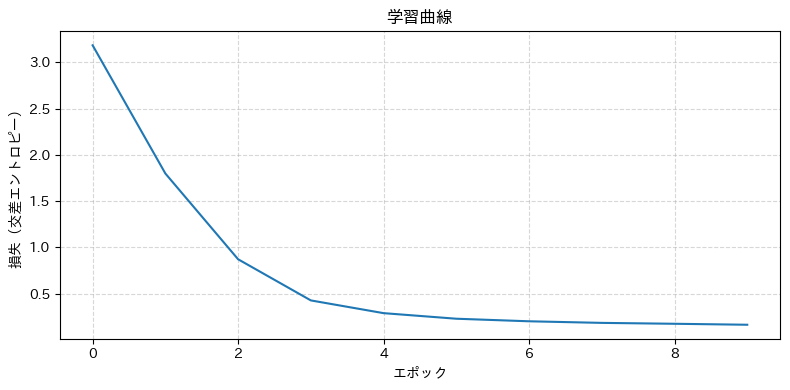

最初の損失: 3.1836  最後の損失: 0.1624


In [21]:
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("エポック")
plt.ylabel("損失（交差エントロピー）")
plt.title("学習曲線")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"最初の損失: {losses[0]:.4f}  最後の損失: {losses[-1]:.4f}")

### 学習後のモデルで生成する

学習後のモデルで、いくつかのプロンプトから続きを生成してみます。

In [22]:
for prompt in ["むかし、むかし、", "桃太郎は", "おじいさんとおばあさんは"]:
    text = generate(
        model,
        tokenizer,
        prompt=prompt,
        max_new_tokens=120,
        block_size=block_size,
    )
    continuation = text[len(prompt) :]
    print(text)
    print("-----------------")

むかし、むかし、あるとこに、おじいさんは言《い》いました。
「気《き》をつけて、けがをしないようにおしよ。」
　とおばあさんも言《い》いました。
　そこで、おじいさんとおばあさんは、こっきっと、桃太郎《ももたろう》のあとから、ついて行ってました。

こうそ
-----------------
桃太郎はこいう》だんごをこうてました。
　桃太郎《ももたろう》は十五になりました。
　もうそのじぶんには、日本《にほん》の国中《くにじゅう》で、桃太郎《ももたろう》ほど強《つよ》いものはないようになりました。桃太郎《ももたろう》はどこか外国《がいこ
-----------------
おじいさんとおばあさんは、こう言《い》って顔《かお》を見合《みあ》わせながら、「あッは、あッは。」とおも言《い》いました。

「まあ、まあ、けががなくって、何《なに》よりさ。」
　とおばあさんは言《い》いました。
　桃太郎《ももたろう》は、その時《とき》やだしくそ
-----------------


学習前に比べて日本語らしくなりました。学習データに存在するテキストの断片をつなぎ合わせるような挙動が見て取れます。

## まとめ

- スケール化内積注意・因果マスク・マルチヘッド注意・層正規化・フィードフォワード層・残差接続を、線形層と活性化関数だけで実装しました。
- それらを Pre-LN のデコーダブロックにまとめ、埋め込み・位置エンコーディング・出力層と組み合わせてデコーダ型 Transformer を構成しました。
- 後半の実験で『桃太郎』の本文を文字 ID に変換して次トークン予測を学習させ、**損失の推移**と**学習前後の生成結果**を観察しました。
- 一方で、この規模のコーパスではモデルが丸暗記できてしまいます。一般化を確かめるには、学習に使っていない文章での評価が必要です。
- ニューラル N-gram との違いは、文脈の重み付けを注意機構でデータから学習する点にあります。この仕組みが現代の大規模言語モデルの基盤になっています。

## 実験してみよう

ハイパーパラメータを変えて、挙動の変化を観察してみましょう。

- **モデルの大きさを変える**：パラメータ数を増やすと、学習データの再現率は上がるでしょうか。逆に小さくするとどうなるでしょうか。
- **文脈長を変える**：`block_size` を 8 や 64 に変えると、言い回しのつながりはどう変わるでしょうか。
